# Hull Tactical – Market Prediction

매 거래일 S&P 500 보유 비중 `w ∈ [0, 2]` 예측


```
z = Ridge(alpha=1000) 예측값 / 학습 구간 예측 표준편차
w = clip(1 + 0.05 · z, 0, 2)
```

# 1. 설정 & 데이터 로드

In [1]:
import os, sys
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

DATA_DIR = './data'
train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test.csv')

TARGETS = ['forward_returns', 'risk_free_rate', 'market_forward_excess_returns']
RAW_FEATS = [c for c in train.columns if c not in TARGETS + ['date_id']]
print(train.shape, test.shape, '| 피처', len(RAW_FEATS))

(9048, 98) (10, 99) | 피처 94


# 2. EDA

0        9
1006    63
1511     3
1512     1
1574     1
1616     2
1638     1
1784     1
2018     1
3009     1
3217     1
3283     1
3537     1
4539     1
5043     1
5540     2
5547     1
5733     1
6049     1
6969     1


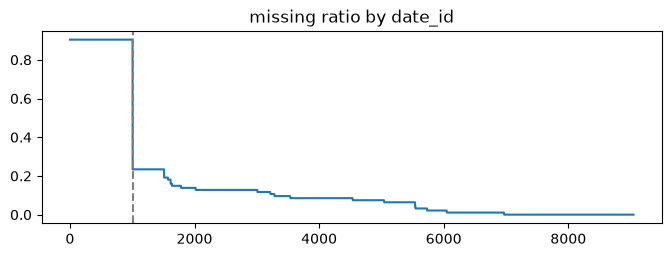

In [2]:
# 결측 구조: 피처별 첫 유효 date_id
first_valid = train[RAW_FEATS].apply(lambda s: train.date_id[s.first_valid_index()])
print(first_valid.value_counts().sort_index().to_string())
train[RAW_FEATS].isna().mean(axis=1).plot(figsize=(8, 2.5), title='missing ratio by date_id')
plt.axvline(1006, ls='--', c='gray'); plt.show()

In [3]:
# 수익률은 거의 예측 불가, 변동성은 군집 / 단일 피처 신호는 약함
fr = train.forward_returns
print(f'수익률 자기상관 {fr.autocorr():.3f} | |수익률| 자기상관 {fr.abs().autocorr():.3f}')
corr = train[train.date_id >= 1006][RAW_FEATS].corrwith(train.market_forward_excess_returns, method='spearman')
print(f'단일 피처 |Spearman| 최대 {corr.abs().max():.3f} ({corr.abs().idxmax()}), 0.03 초과 {int((corr.abs() > 0.03).sum())}개')

수익률 자기상관 -0.045 | |수익률| 자기상관 0.231
단일 피처 |Spearman| 최대 0.054 (M1), 0.03 초과 12개


- 결측: 94개 중 9개(D)만 처음부터 존재, 63개는 `date_id 1006`부터, 나머지는 1511~6969 사이에 시작함. → 학습은 1006 이후로 하고, 남은 결측은 학습 구간 median으로 채움.
- 수익률 구조: 수익률 자기상관 −0.045로 거의 없음, |수익률| 자기상관 0.23으로 변동성 군집이 뚜렷함. → 방향 예측은 매우 어려움.
- 단일 피처 신호: 상관 최대 0.054로 약함. → 여러 피처를 강한 정규화 선형 모델로 결합함.

# 3. 평가지표 & 기준선
전략 수익률: `rf·(1−w) + w·fwd`, 점수는 Sharpe를 두 페널티로 나눈 값
- 변동성 페널티: 전략 변동성이 시장의 1.2배 초과 시 적용
- 수익률 페널티: 전략 수익률이 시장보다 낮으면 차이의 제곱에 비례해 적용

검증: 최근 24개 구간(구간당 180거래일)

In [4]:
def hull_score(fwd, rf, pos):
    fwd, rf, pos = (np.asarray(a, dtype=float) for a in (fwd, rf, pos))
    strat = rf * (1 - pos) + pos * fwd
    n = len(strat)
    s_mean = np.prod(1 + strat - rf) ** (1 / n) - 1
    s_std = strat.std(ddof=1)
    sharpe = s_mean / s_std * np.sqrt(252)
    m_mean = np.prod(1 + fwd - rf) ** (1 / n) - 1
    m_std = fwd.std(ddof=1)
    vol_pen = 1 + max(0, s_std / m_std - 1.2)
    ret_pen = 1 + max(0, (m_mean - s_mean) * 100 * 252) ** 2 / 100
    return sharpe / (vol_pen * ret_pen)

START, PURGE, B, N_FOLDS = 1006, 5, 180, 24
fold_ends = [len(train) - B * i for i in range(N_FOLDS)][::-1]

base = pd.DataFrame([{f'w={w}': hull_score(train.forward_returns[e - B:e], train.risk_free_rate[e - B:e], np.full(B, w))
                      for w in (0.5, 0.8, 1.0, 1.2, 1.5)} for e in fold_ends])
print(base.agg(['mean', 'std', 'min', 'max']).round(3))

      w=0.5  w=0.8  w=1.0  w=1.2  w=1.5
mean  0.447  0.780  0.952  0.946  0.727
std   0.476  0.854  1.079  1.068  0.803
min  -0.557 -0.611 -0.648 -0.488 -0.257
max   1.468  2.864  3.491  3.484  2.673


- 고정 비중 중 w=1이 최고(평균 0.952). 1보다 낮추면 수익률 페널티, 높이면 변동성 페널티를 받음.
- 구간별 점수 편차(표준편차 1.08)가 모델 간 차이보다 훨씬 큼. → w=1 대비 개선의 일관성(t-통계)으로 평가

# 4. 피처

| 피처 | 정의 |
|---|---|
| 원본 94개 | D/E/I/M/P/S/V |
| `mom_{5,21,63,252}` | 최근 N일 누적 수익률 |
| `rv_{5,21,63}`, `ewv` | 실현변동성, 반감기 21일 EWMA 변동성 |
| `rv_ratio` | `rv_5 / rv_63` |
| `ex_lag` | 전일 초과수익률 |

In [5]:
LAG_COLS = ['lagged_' + c for c in TARGETS]

def add_lagged(d):
    d = d.copy()
    for c in TARGETS:
        d['lagged_' + c] = d[c].shift(1)
    return d

def make_features(d):
    r = d['lagged_forward_returns']
    f = pd.DataFrame(index=d.index)
    for w in (5, 21, 63, 252):
        f[f'mom_{w}'] = r.rolling(w, min_periods=w // 2).sum()
    for w in (5, 21, 63):
        f[f'rv_{w}'] = r.rolling(w, min_periods=w // 2).std()
    f['ewv'] = np.sqrt((r ** 2).ewm(halflife=21, min_periods=10).mean())
    f['rv_ratio'] = f['rv_5'] / f['rv_63']
    f['ex_lag'] = d['lagged_market_forward_excess_returns']
    return pd.concat([d[RAW_FEATS], f], axis=1)

df = add_lagged(train)
X, y = make_features(df), df['market_forward_excess_returns']

# test의 lagged 값이 train shift(1)과 같은지 확인
m = test[['date_id', 'lagged_forward_returns']].merge(df[['date_id', 'lagged_forward_returns']], on='date_id')
print('피처 수', X.shape[1], '| lagged 일치:', np.allclose(m.iloc[:, 1], m.iloc[:, 2]))

피처 수 104 | lagged 일치: True


# 5. 평가 체계
## 5.1 공통 인터페이스
- `fit(train)`: 정답 컬럼이 포함된 과거 데이터로 학습
- `predict(hist, n)`: 정답 컬럼이 없는 이력(피처, `lagged_*`)을 받아 마지막 n일 비중을 반환

In [6]:
HIST_COLS = ['date_id'] + RAW_FEATS + LAG_COLS
TAIL = 1000   # 피처 계산에 쓰는 최근 이력 (최장 창 252일 + EWMA 여유)

class RidgeZ:
    # 결측: 학습 median → z-score → ±5 clip → 0. 출력은 학습 구간 예측 표준편차로 나눈 z 점수
    def __init__(self, alpha): self.alpha = alpha
    def fit(self, Xt, yt):
        self.med, self.mu, self.sd = Xt.median(), Xt.mean(), Xt.std() + 1e-12
        self.m = Ridge(alpha=self.alpha).fit(self._z(Xt), yt)
        self.scale = self.m.predict(self._z(Xt)).std()
        return self
    def _z(self, A):
        return ((A.fillna(self.med) - self.mu) / self.sd).clip(-5, 5).fillna(0)
    def predict_z(self, A):
        return self.m.predict(self._z(A)) / self.scale

class RidgeStrategy:
    # 최종 모델: w = clip(1 + k·z, 0, 2)
    def __init__(self, alpha=1000, k=0.05): self.alpha, self.k = alpha, k
    def fit(self, train):
        Xt = make_features(train)
        keep = train.date_id >= START
        self.model = RidgeZ(self.alpha).fit(Xt[keep], train.loc[keep, 'market_forward_excess_returns'])
        return self
    def predict_z(self, hist, n):
        return self.model.predict_z(make_features(hist.tail(n + TAIL)).iloc[-n:])
    def predict(self, hist, n):
        return np.clip(1 + self.k * self.predict_z(hist, n), 0, 2)

class ConstStrategy:
    # 고정 비중 기준선
    def __init__(self, w=1.0): self.w = w
    def fit(self, train): return self
    def predict(self, hist, n): return np.full(n, self.w)

## 5.2 평가 함수와 스코어카드

| 구분 | 지표 | 의미 |
|---|---|---|
| 주 지표 | 승률, t-통계 | w=1 대비 개선의 일관성 (실제 채점은 180일 구간 한 번) |
| | 평균·중앙값 개선 | 개선 크기 |
| 분해 | 타이밍 기여 | 모델 점수 − **같은 평균 비중의 고정 전략** 점수 (레버리지 효과 제거) |
| | 레버리지 효과 | 평균 비중 고정 전략 − w=1 |
| 위험 | 변동성 비율 최대 | 전략/시장 변동성 비율의 fold 최댓값 (1.2 초과 시 페널티) |
| | 수익률 열위 fold 비율 | 전략 수익률 < 시장 수익률인 fold 비율 (수익률 페널티 발생) |
| 강건성 | 순열 검정 p | fold 안에서 비중 순서를 섞은 귀무 전략 1000개 대비 유의성 (타이밍이 진짜인지) |
| | 상위 1 fold 집중도 | 가장 큰 fold 개선 ÷ 전체 개선 합 |
| | 시간 추세 | fold 순서와 개선의 순위 상관 (음수면 edge 감소) |
| | 강세/약세 국면 개선 | fold의 시장 수익률 부호로 나눈 평균 개선 |

In [7]:
N_FOLDS, VAULT_FOLDS = 24, 4
DEV_FOLDS = list(range(N_FOLDS - VAULT_FOLDS))
VAULT = list(range(N_FOLDS - VAULT_FOLDS, N_FOLDS))
VAULT_START = fold_ends[VAULT[0]] - B
print(f'개발 fold {len(DEV_FOLDS)}개: date_id {df.date_id[fold_ends[0] - B]} ~ {df.date_id[VAULT_START - 1]}')
print(f'vault fold {len(VAULT)}개: date_id {df.date_id[VAULT_START]} ~ {df.date_id.iloc[-1]}  (최종 확정 후 1회만 평가)')

def fold_stats(g, w):
    fwd, rf = g.forward_returns.values, g.risk_free_rate.values
    strat = rf * (1 - w) + w * fwd
    return {'score': hull_score(fwd, rf, w), 'base': hull_score(fwd, rf, np.ones(len(w))),
            'const': hull_score(fwd, rf, np.full(len(w), w.mean())), 'w_mean': w.mean(),
            'vol_ratio': strat.std() / fwd.std(), 'ret_behind': np.prod(1 + strat - rf) < np.prod(1 + fwd - rf),
            'mkt_up': np.prod(1 + fwd) > 1}

def evaluate(make_strategy, folds=DEV_FOLDS):
    rows, W = [], {}
    for f in folds:
        e = fold_ends[f]; v0 = e - B
        strat = make_strategy().fit(df.iloc[:v0 - PURGE])
        w = np.asarray(strat.predict(df.iloc[:e][HIST_COLS], B), dtype=float)
        rows.append({'fold': f, **fold_stats(df.iloc[v0:e], w)}); W[f] = w
    res = pd.DataFrame(rows)
    res['diff'] = res.score - res.base
    return res, W

def tstat(d):
    d = np.asarray(d, dtype=float)
    return d.mean() / d.std(ddof=1) * np.sqrt(len(d))

def perm_pvalue(res, W, n_perm=1000, seed=0):
    rng = np.random.default_rng(seed)
    obs = res['diff'].mean()
    null = np.zeros(n_perm)
    for f in res.fold:
        g = df.iloc[fold_ends[f] - B:fold_ends[f]]
        base = res.loc[res.fold == f, 'base'].iloc[0]
        null += [hull_score(g.forward_returns, g.risk_free_rate, rng.permutation(W[f])) - base for _ in range(n_perm)]
    null /= len(res)
    return (np.sum(null >= obs) + 1) / (n_perm + 1), null

def scorecard(res, W, perm=True):
    d = res['diff']
    pos = d[d > 0]
    return pd.Series({
        '평균 개선': d.mean(), '중앙값 개선': d.median(), '승률': (d > 0).mean(), 't-통계': tstat(d),
        '타이밍 기여': (res.score - res.const).mean(), '타이밍 승률': (res.score > res.const).mean(),
        '레버리지 효과': (res.const - res.base).mean(), '평균 비중': res.w_mean.mean(),
        '변동성 비율 최대': res.vol_ratio.max(), '수익률 열위 fold 비율': res.ret_behind.mean(),
        '순열 검정 p': perm_pvalue(res, W)[0] if perm else np.nan,
        '상위1 fold 집중도': d.max() / d[d > 0].sum() if (d > 0).any() else np.nan,
        '시간 추세(ρ)': d.reset_index(drop=True).corr(pd.Series(range(len(d))), method='spearman'),
        '강세 fold 개선': d[res.mkt_up].mean(), '약세 fold 개선': d[~res.mkt_up].mean(),
    })

def compare(res_a, res_b):
    # 같은 fold끼리 paired 비교 (A − B)
    d = res_a.score.values - res_b.score.values
    return pd.Series({'평균 차이': d.mean(), 'A 승률': (d > 0).mean(), 't-통계': tstat(d)})

개발 fold 20개: date_id 4728 ~ 8327
vault fold 4개: date_id 8328 ~ 9047  (최종 확정 후 1회만 평가)


# 6. 개발 구간만으로 모델 재선정
vault를 봉인한 상태에서 개발 20개 fold만으로 Ridge alpha × k를 다시 고름

In [8]:
ALPHAS, KS = [100, 300, 1000, 3000, 10000, 30000], [0.05, 0.1, 0.2]
grid = []
for a in ALPHAS:
    for f in DEV_FOLDS:   # alpha당 한 번만 학습하고, k는 z에서 바로 비중 계산
        e = fold_ends[f]; v0 = e - B
        z = RidgeStrategy(a).fit(df.iloc[:v0 - PURGE]).predict_z(df.iloc[:e][HIST_COLS], B)
        g = df.iloc[v0:e]
        base = hull_score(g.forward_returns, g.risk_free_rate, np.ones(B))
        for k in KS:
            grid.append({'alpha': a, 'k': k, 'fold': f, 'diff': hull_score(g.forward_returns, g.risk_free_rate, np.clip(1 + k * z, 0, 2)) - base})
grid = pd.DataFrame(grid)
sel = grid.groupby(['alpha', 'k'])['diff'].agg(t=tstat, mean='mean', win=lambda d: (d > 0).mean())
print(sel['t'].unstack('k').round(2))
ALPHA, K = sel['t'].idxmax()
print(f'\n개발 구간 선택: alpha={ALPHA}, k={K}  (t={sel.t.max():.2f})')

k      0.05  0.10  0.20
alpha                  
100    4.74  4.37  3.86
300    5.73  4.78  4.29
1000   6.73  5.90  4.56
3000   5.73  4.48  2.60
10000  3.84  2.39  1.00
30000  2.42  1.27  0.43

개발 구간 선택: alpha=1000, k=0.05  (t=6.73)


# 7. 스코어카드 (개발 20 fold)
| 비교 대상 | 설명 |
|---|---|
| 최종 모델 | Ridge 설정 |
| LGB 모델 | 1단계 LightGBM |
| w=1.2 고정 | 레버리지만 쓴 기준선 |

In [9]:
import lightgbm as lgb

class LGBStrategy:
    def __init__(self, k=0.05): self.k = k
    def fit(self, train):
        Xt, keep = make_features(train), train.date_id >= START
        yt = train.loc[keep, 'market_forward_excess_returns']
        self.m = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.01, num_leaves=8, min_child_samples=200,
                                   subsample=0.7, subsample_freq=1, colsample_bytree=0.5, reg_lambda=10, verbose=-1).fit(Xt[keep], yt)
        self.scale = self.m.predict(Xt[keep]).std()
        return self
    def predict(self, hist, n):
        z = self.m.predict(make_features(hist.tail(n + TAIL)).iloc[-n:]) / self.scale
        return np.clip(1 + self.k * z, 0, 2)

CANDIDATES = {
    '최종 모델': lambda: RidgeStrategy(ALPHA, K),
    'LGB 모델': lambda: LGBStrategy(K),
    'w=1.2 고정': lambda: ConstStrategy(1.2),
}
RES = {name: evaluate(fn) for name, fn in CANDIDATES.items()}
card = pd.DataFrame({name: scorecard(r, W) for name, (r, W) in RES.items()})
card.round(3)

,최종 모델,LGB 모델,w=1.2 고정
평균 개선,0.047,0.022,-0.004
중앙값 개선,0.050,0.026,-0.015
승률,0.900,0.700,0.100
t-통계,6.730,2.633,-0.500
타이밍 기여,0.048,0.026,-0.000
타이밍 승률,0.900,0.800,0.250
레버리지 효과,-0.001,-0.004,-0.004
평균 비중,1.017,0.998,1.200
변동성 비율 최대,1.182,1.090,1.200
수익률 열위 fold 비율,0.200,0.400,0.250


       최종 모델 vs LGB 모델  최종 모델 vs w=1.2 고정
평균 차이            0.026              0.052
A 승률             0.850              0.950
t-통계             3.229              5.207


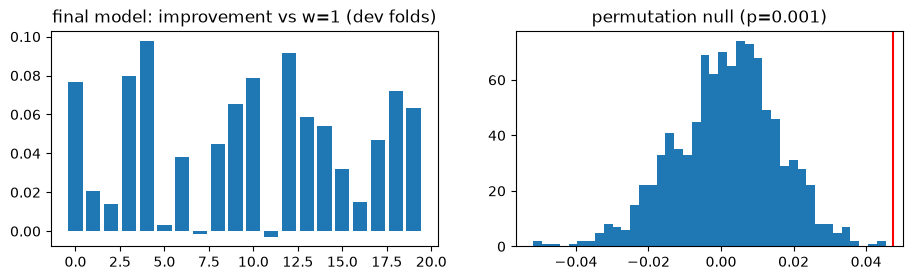

In [10]:
# paired 비교: 최종 모델 vs 다른 후보
print(pd.DataFrame({f'최종 모델 vs {n}': compare(RES['최종 모델'][0], RES[n][0]) for n in RES if n != '최종 모델'}).round(3))

r, W = RES['최종 모델']
p, null = perm_pvalue(r, W)
fig, ax = plt.subplots(1, 2, figsize=(11, 2.8))
ax[0].bar(r.fold, r['diff']); ax[0].set_title('final model: improvement vs w=1 (dev folds)')
ax[1].hist(null, bins=40); ax[1].axvline(r['diff'].mean(), c='r'); ax[1].set_title(f'permutation null (p={p:.3f})')
plt.show()

In [11]:
# 민감도: 선택 설정 주변의 t-통계가 고원 형태인지 확인
near = sel.loc[[(a, k) for a in ALPHAS for k in KS if a in (ALPHA // 3 if ALPHA >= 300 else ALPHA, ALPHA, ALPHA * 3)]]
print(near.round(3))

                t   mean   win
alpha k                       
1000  0.05  6.730  0.047  0.90
      0.10  5.900  0.093  0.90
      0.20  4.565  0.151  0.85
3000  0.05  5.734  0.041  0.90
      0.10  4.481  0.074  0.90
      0.20  2.603  0.104  0.85


# 8. Vault 평가 & Pseudo-forward 시뮬레이션
1. Vault fold 평가: 4개 fold 각각 직전까지의 데이터로 재학습(주기적 재학습 운영에 해당)
2. Pseudo-forward: vault 시작 전까지 학습한 모델을 고정하고, 제출과 같은 경로로 720일을 하루씩 실행

In [12]:
vault_res = {name: evaluate(fn, VAULT)[0] for name, fn in CANDIDATES.items()}
print(pd.DataFrame({name: r.set_index('fold')['diff'] for name, r in vault_res.items()}).round(3))
print(pd.DataFrame({name: {'평균 개선': r['diff'].mean(), '승률': (r['diff'] > 0).mean()} for name, r in vault_res.items()}).round(3))

      최종 모델  LGB 모델  w=1.2 고정
fold                         
20    0.024   0.028    -0.013
21   -0.033  -0.013    -0.011
22   -0.003   0.021    -0.015
23    0.011  -0.135    -0.016
       최종 모델  LGB 모델  w=1.2 고정
평균 개선   -0.0  -0.025    -0.014
승률       0.5   0.500     0.000


   window  score   base   diff  w_mean  vol_ratio
0       0  0.634  0.610  0.024   0.954      0.964
1       1  2.454  2.494 -0.041   0.981      0.995
2       2  0.148  0.143  0.005   0.994      1.014
3       3  1.125  1.126 -0.001   1.014      1.066
720일 전체: 모델 1.004 vs w=1 1.008


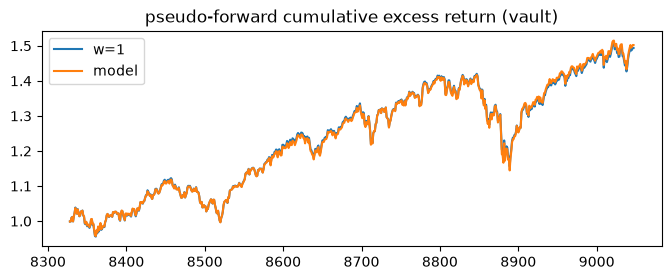

In [13]:
def make_predict(strategy, init_hist):
    state = {'hist': init_hist.copy()}
    def predict(test: pl.DataFrame) -> float:
        row = test.to_pandas()[HIST_COLS].apply(pd.to_numeric, errors='coerce')
        h = state['hist']
        state['hist'] = pd.concat([h[h.date_id < row.date_id.iloc[0]], row], ignore_index=True)
        return float(strategy.predict(state['hist'], 1)[0])
    return predict

frozen = RidgeStrategy(ALPHA, K).fit(df.iloc[:VAULT_START])
pf_predict = make_predict(frozen, df.iloc[:VAULT_START][HIST_COLS])
vault_rows = df.iloc[VAULT_START:]
w_pf = np.array([pf_predict(pl.from_pandas(vault_rows.iloc[[i]][HIST_COLS])) for i in range(len(vault_rows))])

pf = pd.DataFrame([{'window': i, **fold_stats(vault_rows.iloc[i * B:(i + 1) * B], w_pf[i * B:(i + 1) * B])} for i in range(len(VAULT))])
pf['diff'] = pf.score - pf.base
print(pf[['window', 'score', 'base', 'diff', 'w_mean', 'vol_ratio']].round(3))
print(f"720일 전체: 모델 {hull_score(vault_rows.forward_returns, vault_rows.risk_free_rate, w_pf):.3f} vs w=1 {hull_score(vault_rows.forward_returns, vault_rows.risk_free_rate, np.ones(len(w_pf))):.3f}")

ex = vault_rows.forward_returns - vault_rows.risk_free_rate
plt.figure(figsize=(8, 2.8))
plt.plot(vault_rows.date_id, (1 + ex).cumprod(), label='w=1'); plt.plot(vault_rows.date_id, (1 + w_pf * ex).cumprod(), label='model')
plt.legend(); plt.title('pseudo-forward cumulative excess return (vault)'); plt.show()

| | 개발 20 fold | Vault 4 fold | Pseudo-forward (720일) |
|---|---|---|---|
| 최종 모델 개선 | +0.047 (승률 90%) | **−0.000 (승률 50%)** | 구간별 +0.024 / −0.041 / +0.005 / −0.001 |
| LGB 모델 개선 | +0.022 | −0.025 | — |
| 평균 IC | 0.081 | **0.043** | — |

## 8.1 다른 모델과의 비교 (walk-forward)
같은 평가 체계(`evaluate`, 24개 fold × 180일)로 팀 내 다른 후보와 비교

| 모델 | 설정 |
|---|---|
| narin (최종 제출) | 본 노트북 모델: Ridge(alpha=1000), 피처 ±5 clip, `w = 1 + 0.05·z` |
| Maddox | Ridge(alpha=3000), 원본 94개 + 전일 초과수익률 이동평균·표준편차(5/20/60일), 2000일 이후 학습, `w = 1 + 0.1·z` |
| A안 | Maddox + 변동성 조절: `w = 1 + 0.1·z·√(평소 20일 변동성 / 최근 20일 변동성)` |

w=1 평균 점수 (개발 20 fold): 0.924


,narin (최종 제출),Maddox,A안
평균 점수,0.971,1.059,1.046
w=1 대비 평균 개선,0.047,0.136,0.122
승률,0.900,0.950,0.950
t-통계,6.730,5.891,6.541
최악 fold 개선,-0.003,-0.022,-0.013
변동성 비율 평균,1.043,1.106,1.084
변동성 비율 최대,1.182,1.551,1.353
변동성 페널티 fold 수 (>1.2),0.000,5.000,5.000
vault 평균 개선,-0.000,-0.017,-0.018
vault 승률,0.500,0.500,0.500


,narin − Maddox,narin − A안
평균 차이,-0.088,-0.075
narin 승률,0.100,0.150
t-통계,-4.003,-4.159


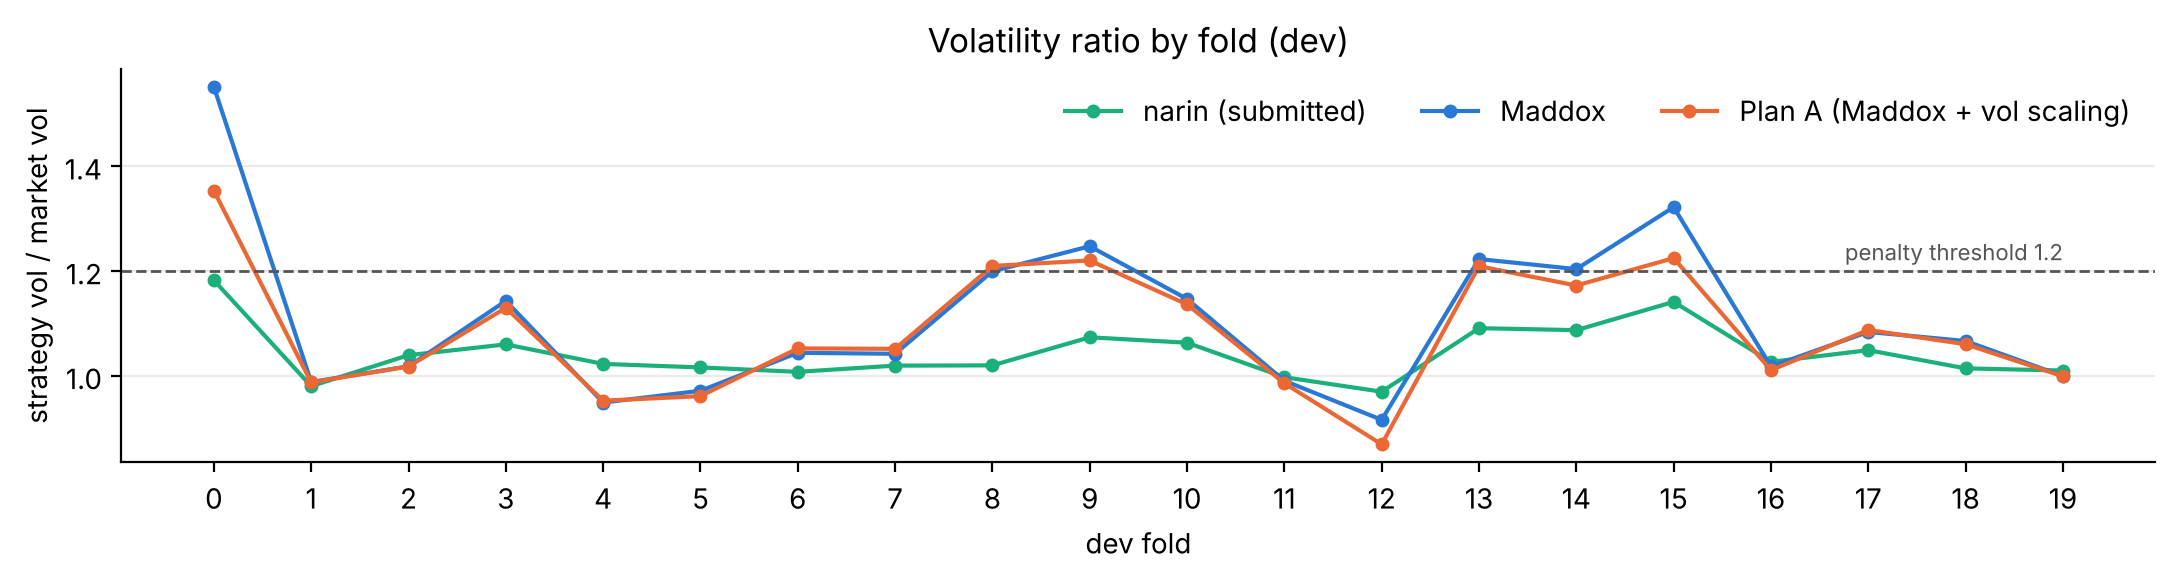

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from IPython.display import display

def mx_features(d):
    # Maddox / A안 피처: 원본 94개 + 전일 초과수익률과 그 5/20/60일 이동평균·표준편차
    r = d['lagged_market_forward_excess_returns']
    f = pd.DataFrame({'ex_lag': r}, index=d.index)
    for w in (5, 20, 60):
        f[f'ret_mean_{w}'] = r.rolling(w).mean()
        f[f'ret_vol_{w}'] = r.rolling(w).std()
    f['vol_ratio_5_60'] = f['ret_vol_5'] / f['ret_vol_60']
    return pd.concat([d[RAW_FEATS], f], axis=1)

class MaddoxStrategy:
    # vol_scaled=True → A안 (최근 20일 변동성이 평소보다 크면 기울기를 줄임)
    def __init__(self, k=0.1, alpha=3000, vol_scaled=False):
        self.k, self.alpha, self.vol_scaled = k, alpha, vol_scaled
    def fit(self, train):
        X, keep = mx_features(train), train.date_id >= 2000
        Xt, yt = X[keep], train.loc[keep, 'market_forward_excess_returns']
        self.m = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=self.alpha)).fit(Xt, yt)
        p = self.m.predict(Xt)
        self.mu, self.sd, self.vol_ref = p.mean(), p.std(), Xt['ret_vol_20'].median()
        return self
    def predict(self, hist, n):
        X = mx_features(hist.tail(n + TAIL)).iloc[-n:]
        z = (self.m.predict(X) - self.mu) / self.sd
        if self.vol_scaled:
            s = np.sqrt(self.vol_ref / X['ret_vol_20'].values)
            z = z * np.where(np.isfinite(s), s, 1.0)
        return np.clip(1 + self.k * z, 0, 2)

COMPARE = {'narin (최종 제출)': lambda: RidgeStrategy(ALPHA, K),
           'Maddox': lambda: MaddoxStrategy(),
           'A안': lambda: MaddoxStrategy(vol_scaled=True)}
import warnings
with warnings.catch_warnings():   # 학습 구간에 값이 하나도 없는 피처(E7 등)는 imputer가 건너뜀 → 경고만 숨김
    warnings.simplefilter('ignore', UserWarning)
    cmp_dev = {n: evaluate(fn)[0] for n, fn in COMPARE.items()}
    cmp_vault = {n: evaluate(fn, VAULT)[0] for n, fn in COMPARE.items()}

summary = pd.DataFrame({n: {
    '평균 점수': r.score.mean(), 'w=1 대비 평균 개선': r['diff'].mean(), '승률': (r['diff'] > 0).mean(),
    't-통계': tstat(r['diff']), '최악 fold 개선': r['diff'].min(),
    '변동성 비율 평균': r.vol_ratio.mean(), '변동성 비율 최대': r.vol_ratio.max(),
    '변동성 페널티 fold 수 (>1.2)': int((r.vol_ratio > 1.2).sum()),
    'vault 평균 개선': cmp_vault[n]['diff'].mean(), 'vault 승률': (cmp_vault[n]['diff'] > 0).mean(),
} for n, r in cmp_dev.items()})
print(f"w=1 평균 점수 (개발 20 fold): {cmp_dev['Maddox'].base.mean():.3f}")
display(summary.round(3))

nar = cmp_dev['narin (최종 제출)']
# 같은 fold끼리 paired 비교 (narin − 다른 모델)
display(pd.DataFrame({f'narin − {n}': compare(nar, r) for n, r in cmp_dev.items() if n != 'narin (최종 제출)'})
        .rename(index={'A 승률': 'narin 승률'}).round(3))

colors = {'narin (최종 제출)': '#1baf7a', 'Maddox': '#2a78d6', 'A안': '#eb6834'}
labels = {'narin (최종 제출)': 'narin (submitted)', 'Maddox': 'Maddox', 'A안': 'Plan A (Maddox + vol scaling)'}
fig, ax = plt.subplots(figsize=(11, 3))
for n, r in cmp_dev.items():
    ax.plot(r.fold, r.vol_ratio, marker='o', ms=4, lw=1.5, color=colors[n], label=labels[n])
ax.axhline(1.2, color='#555', lw=1, ls='--'); ax.text(r.fold.max(), 1.21, 'penalty threshold 1.2', ha='right', va='bottom', fontsize=8, color='#555')
ax.set_xticks(r.fold); ax.set_xlabel('dev fold'); ax.set_ylabel('strategy vol / market vol')
ax.set_title('Volatility ratio by fold (dev)'); ax.grid(axis='y', alpha=0.25); ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=3, loc='upper right'); plt.tight_layout(); plt.show()

| | narin (최종 제출) | Maddox | A안 |
|---|---|---|---|
| 개발 평균 점수 (w=1: 0.924) | 0.971 | **1.059** | 1.046 |
| 개선 t-통계 | **6.73** | 5.89 | 6.54 |
| 최악 fold 개선 | **−0.003** | −0.022 | −0.013 |
| 변동성 비율 평균 / 최대 | **1.043 / 1.182** | 1.106 / 1.551 | 1.084 / 1.353 |
| 변동성 페널티 fold 수 | **0** | 5 | 5 |
| vault 평균 개선 | **−0.000** | −0.017 | −0.018 |

- 점수 크기: Maddox·A안이 narin보다 개발 구간 평균 0.075~0.088 높음
- 변동성·안정성: narin은 20개 fold 모두 변동성 비율이 1.2 이하로 변동성 페널티를 한 번도 받지 않음. 최악 fold 손실도 가장 작고, 개선의 일관성(t)도 가장 높음
- 최근 구간(vault): 세 모델 모두 w=1과 비슷하지만 narin이 가장 덜 잃음. 신호가 약해진 시기에는 작은 베팅이 유리함
- vault 개선이 가장 중요하여 narin 모델로 채택

# 9. 최종 학습

In [14]:
final = RidgeStrategy(ALPHA, K).fit(df)
predict = make_predict(final, df[HIST_COLS])

# 점검: predict() 경로 결과 == 전체 이력으로 계산한 오프라인 결과
check = make_predict(final, df[HIST_COLS])
online = [check(pl.from_pandas(test.iloc[[i]])) for i in range(len(test))]
offline = final.predict(df[HIST_COLS][df.date_id <= test.date_id.max()], len(test))
print('최대 차이:', np.abs(np.array(online) - offline).max())

최대 차이: 1.1102230246251565e-16
